![](img/banner.png)

# Naive Bayes Classification

**Mahmood Amintoosi, Fall 2026**

Computer Science Dept, Ferdowsi University of Mashhad

The decision rule is the one of chapter 2 of *Pattern Classification* by Duda, Hart, and Stork
({cite}`Duda2000`); the insect example is from a set of
[slides by Eamonn Keogh](https://www.cs.ucr.edu/~eamonn/CE/Bayesian%20Classification%20withInsect_examples.pdf).
The Gaussian and multinomial sections follow VanderPlas ({cite}`vanderplas2016python`).

**Learning objectives.** By the end you should be able to

1. write Bayes' theorem for a classification problem and name its four terms;
2. classify an object from a histogram of one feature;
3. apply the naive assumption and compute a posterior from several discrete features;
4. explain what a single zero count does to the product, and fix it with Laplace smoothing;
5. fit and read a Gaussian and a multinomial naive Bayes classifier with Scikit-Learn;
6. say when naive Bayes is a good baseline and when its independence assumption fails.


## Bayes' Theorem

Bayes' Theorem is a fundamental principle in probability theory that describes how to update our beliefs about an event based on new evidence. It provides a mathematical framework for calculating conditional probabilities, specifically the probability of an event occurring given that another event has already occurred. The theorem is named after the Reverend Thomas Bayes, who first formulated this principle in the 18th century.


![](img/BCW_page_01.jpg)

**Thomas Bayes 1702 - 1761**

The mathematical formula for Bayes' Theorem is expressed as:

$$P(A|B) = \frac{P(B|A) \times P(A)}{P(B)}$$

Where:
- $P(A|B)$ is the **posterior probability**: the probability of event A occurring given that B is true
- $P(B|A)$ is the **likelihood**: the probability of event B occurring given that A is true
- $P(A)$ is the **prior probability**: the initial probability of event A
- $P(B)$ is the **marginal probability**: the total probability of event B occurring

### Example with Dice

Suppose we have two dice: one fair die (with equal probability of rolling 1-6) and one loaded die that always shows 6. We randomly select one die and roll it, getting a 6. What is the probability that we selected the loaded die?

Let's define our events:
- Event A: Selecting the loaded die
- Event B: Rolling a 6

Given:
- $P(A) = \frac{1}{2}$ (equal chance of selecting either die)
- $P(B|A) = 1$ (loaded die always shows 6)
- $P(B|A^c) = \frac{1}{6}$ (fair die shows 6 with probability 1/6)
- $P(B) = P(B|A) \times P(A) + P(B|A^c) \times P(A^c) = 1 \times \frac{1}{2} + \frac{1}{6} \times \frac{1}{2} = \frac{1}{2} + \frac{1}{12} = \frac{7}{12}$

Applying Bayes' Theorem:
$$P(A|B) = \frac{P(B|A) \times P(A)}{P(B)} = \frac{1 \times \frac{1}{2}}{\frac{7}{12}} = \frac{\frac{1}{2}}{\frac{7}{12}} = \frac{1}{2} \times \frac{12}{7} = \frac{6}{7}$$

So given that we rolled a 6, there is a $\frac{6}{7}$ (approximately 85.7%) probability that we selected the loaded die.

## Bayes Classifiers

Bayes' theorem turns a model of the data into a decision rule. For a class $\omega_j$ and an
observed feature vector $\mathbf{x}$,

$$
P(\omega_j \mid \mathbf{x}) = \frac{p(\mathbf{x} \mid \omega_j)\,P(\omega_j)}{p(\mathbf{x})},
\qquad
p(\mathbf{x}) = \sum_{j=1}^{c} p(\mathbf{x} \mid \omega_j)\,P(\omega_j).
$$

*  $P(\omega_j)$ is the **prior**: how frequent the class is before we look at the object.
*  $p(\mathbf{x} \mid \omega_j)$ is the **likelihood**, or class-conditional density: how
   typical the object is for that class.
*  $P(\omega_j \mid \mathbf{x})$ is the **posterior**.
*  $p(\mathbf{x})$ is the **evidence**. It is the same for all classes, so it only scales the
   posteriors to sum to one and plays no role in the decision.

For two classes the evidence cancels, and the decision depends on the product of likelihood
and prior:

$$
\frac{P(\omega_1 \mid \mathbf{x})}{P(\omega_2 \mid \mathbf{x})}
= \frac{p(\mathbf{x} \mid \omega_1)}{p(\mathbf{x} \mid \omega_2)}\cdot\frac{P(\omega_1)}{P(\omega_2)},
\qquad\text{so}\qquad
i = \arg\max_{j}\; p(\mathbf{x} \mid \omega_j)\,P(\omega_j)
$$

is the **minimum-error decision rule**. The name *naive Bayes* — also *idiot Bayes* or
*simple Bayes* — covers the whole family of classifiers built on this rule. The idea in one
sentence: find the probability of the unseen object for each class, then pick the largest.

The slides in the next two sections write $c_j$ for the class and $d$ for the observed object;
here we write $\omega_j$ and $\mathbf{x}$, as in the
[Bayesian Decision Theory](Bayesian-Decision-Theory.ipynb) page.


## A Visual Example: Grasshoppers and Katydids

by [Eamonn Keogh](https://www.cs.ucr.edu/~eamonn/), CS, UCR.

We have two species, **grasshoppers** and **katydids**, and one feature, antenna length. With
enough data we can build one histogram of antenna length per species.

![](img/BCW_page_02.png)

![](img/BCW_page_03.png)


### Classifying an Insect

We catch an insect whose antennae are 3 units long. Which species is it more probably?

![](img/BCW_page_05.png)

Formally we want, for each class, the conditional probability

$$
P(\omega_j \mid x) \;=\; \text{probability of class } \omega_j \text{ given that we observed } x ,
$$

and we compare the two values.


### Reading the Histogram

Counting the insects of the histogram at antenna length 3:

$$
P(\text{Grasshopper} \mid 3) = \frac{10}{10+2} = 0.833,
\qquad
P(\text{Katydid} \mid 3) = \frac{2}{10+2} = 0.167 .
$$

![](img/BCW_page_06.png)

The same reading at antenna length 7 and at 5:

$$
P(\text{Grasshopper} \mid 7) = \frac{3}{3+9} = 0.250,
\qquad
P(\text{Katydid} \mid 7) = \frac{9}{3+9} = 0.750,
$$

$$
P(\text{Grasshopper} \mid 5) = \frac{6}{6+6} = 0.500,
\qquad
P(\text{Katydid} \mid 5) = \frac{6}{6+6} = 0.500 .
$$

![](img/BCW_page_07.png)

![](img/BCW_page_08.png)

At 3 the insect is a grasshopper, at 7 a katydid, and at 5 the two classes are equally
probable: $x = 5$ is where the decision flips. These ratios are posteriors because the two
counts at a given $x$ are divided by their sum, which is the evidence $p(x)$ of the previous
section.


## Example: Classifying by Name

Two classes, $\omega_1 = \text{male}$ and $\omega_2 = \text{female}$, and one discrete feature,
the first name. We meet a person called *Drew* and ask which posterior is larger,
$P(\text{male} \mid \text{Drew})$ or $P(\text{female} \mid \text{Drew})$. Our whole database of
names and sexes is:

| Name    | Sex    |
|---------|--------|
| Drew    | Male   |
| Claudia | Female |
| Drew    | Female |
| Drew    | Female |
| Alberto | Male   |
| Karin   | Female |
| Nina    | Female |
| Sergio  | Male   |

![](img/BCW_page_12.png)


### Computing the Posteriors

From the table, $P(\text{male}) = 3/8$ and $P(\text{female}) = 5/8$, and inside each class

$$
P(\text{Drew} \mid \text{male}) = \frac{1}{3},
\qquad
P(\text{Drew} \mid \text{female}) = \frac{2}{5}.
$$

The evidence $p(\text{Drew})$ is the same for the two classes, so it is enough to compare the
numerators:

$$
P(\text{male} \mid \text{Drew}) = \frac{\frac{1}{3}\times\frac{3}{8}}{\frac{3}{8}} = \frac{1}{3},
\qquad
P(\text{female} \mid \text{Drew}) = \frac{\frac{2}{5}\times\frac{5}{8}}{\frac{3}{8}} = \frac{2}{5}.
$$

The minimum-error decision for Drew is *female* ($0.40 > 0.33$).

![](img/BCW_page_11.png)

![](img/BCW_page_14.png)


## Several Features and the Naive Assumption

With one feature we could read the posteriors off a histogram. With $d$ features the joint
density $p(\mathbf{x} \mid \omega_j)$ is a table over all combinations of feature values, and
that table grows exponentially with $d$. The **naive Bayes** assumption is that the features
are **conditionally independent** given the class:

$$
p(\mathbf{x} \mid \omega_j) = \prod_{k=1}^{d} p(x_k \mid \omega_j),
$$

so the decision rule needs only $d$ one-dimensional distributions per class:

$$
i = \arg\max_{j}\; P(\omega_j)\,\prod_{k=1}^{d} p(x_k \mid \omega_j).
$$

The assumption is almost never true — in a sentence the words are obviously not independent —
but it keeps the number of parameters linear in $d$, and it usually produces a useful ranking
of the classes even when the probabilities themselves are estimated badly.


### Worked Example: Drew with Three Features

| Name    | Over 170 cm | Eye   | Hair  | Sex    |
|---------|-------------|-------|-------|--------|
| Drew    | No          | Blue  | Short | Male   |
| Claudia | Yes         | Brown | Long  | Female |
| Drew    | No          | Blue  | Long  | Female |
| Drew    | No          | Blue  | Long  | Female |
| Alberto | Yes         | Brown | Short | Male   |
| Karin   | No          | Blue  | Long  | Female |
| Nina    | Yes         | Brown | Short | Female |
| Sergio  | Yes         | Blue  | Long  | Male   |

Take the query $\mathbf{x} = (\text{Yes}, \text{Brown}, \text{Long})$ — tall, brown-eyed, long
hair — and count inside each class:

| Feature value  | $P(\cdot \mid \text{male})$ | $P(\cdot \mid \text{female})$ |
|----------------|-----------------------------|-------------------------------|
| Over 170 = Yes | $2/3$                       | $1/4$                         |
| Eye = Brown    | $1/3$                       | $1/4$                         |
| Hair = Long    | $1/3$                       | $4/4$                         |

With the priors $P(\text{male}) = 3/8$ and $P(\text{female}) = 5/8$ the two scores are

$$
P(\text{male})\prod_k p(x_k \mid \text{male}) = \tfrac{3}{8}\cdot\tfrac{2}{3}\cdot\tfrac{1}{3}\cdot\tfrac{1}{3} = 0.0278,
$$

$$
P(\text{female})\prod_k p(x_k \mid \text{female}) = \tfrac{5}{8}\cdot\tfrac{1}{4}\cdot\tfrac{1}{4}\cdot 1 = 0.0391 .
$$

Dividing by the sum $0.0278 + 0.0391 = 0.0669$ gives the posteriors $0.42$ and $0.58$, and the
decision is *female*. Note what the arithmetic did: the single feature that is much more
likely for females (long hair, $4/4$) outweighed three features that all favour males.

#### The Zero-Count Problem

Now query $\mathbf{x} = (\text{No}, \text{Blue}, \text{Short})$. Among the four females nobody
has short hair, so $P(\text{Short} \mid \text{female}) = 0$ and the product for females is
exactly zero, whatever the other two features say. In the log domain this is worse than a
small probability: $\log 0 = -\infty$.

The standard remedy is **Laplace (add-one) smoothing**,

$$
\hat{p}(x_k = v \mid \omega_j) = \frac{n_{jkv} + 1}{n_j + K_k},
$$

where $n_{jkv}$ counts the value $v$ of feature $k$ in class $j$ and $K_k$ is the number of
values that feature can take. With $+1$ in every cell no likelihood is ever zero: a value that
was never seen gets a small probability instead of a veto. The Scikit-Learn implementations do
this for you (`MultinomialNB(alpha=1)`); for the Gaussian model the analogous guard is
`GaussianNB(var_smoothing=...)`.


## Worked Example: Classifying Fruit

Adapted from [this Stack Overflow answer](https://stackoverflow.com/a/20556654/1013114). The
training set has 1000 fruits, three binary features (*long*, *sweet*, *yellow*) and three
classes:

| Type        | Long | Not long | Sweet | Not sweet | Yellow | Not yellow | Total |
|-------------|------|----------|-------|-----------|--------|------------|-------|
| Banana      | 400  | 100      | 350   | 150       | 450    | 50         | 500   |
| Orange      | 0    | 300      | 150   | 150       | 300    | 0          | 300   |
| Other fruit | 100  | 100      | 150   | 50        | 50     | 150        | 200   |
| **Total**   | 500  | 500      | 650   | 350       | 800    | 200        | 1000  |

### Priors and Likelihoods

The priors are the class totals: $P(\text{Banana}) = 0.5$, $P(\text{Orange}) = 0.3$ and
$P(\text{Other fruit}) = 0.2$. Dividing each cell by its row total gives the likelihoods:

| Feature value | Banana | Orange | Other fruit |
|---------------|--------|--------|-------------|
| Long          | 0.80   | 0.00   | 0.50        |
| Sweet         | 0.70   | 0.50   | 0.75        |
| Yellow        | 0.90   | 1.00   | 0.25        |

The column totals of the training table — 500 long, 650 sweet, 800 yellow — are the feature
marginals. They are *not* needed for the decision, because the evidence $p(\mathbf{x})$ is the
same for the three classes and cancels in the comparison.

### Classifying One Fruit

A new fruit is long, sweet and yellow. Multiplying prior and likelihoods:

| Class       | $P(\omega_j)\prod_k p(x_k \mid \omega_j)$         |
|-------------|----------------------------------------------------|
| Banana      | $0.5 \times 0.8 \times 0.7 \times 0.9 = 0.2520$    |
| Orange      | $0.3 \times 0 \times 0.5 \times 1 = 0$             |
| Other fruit | $0.2 \times 0.5 \times 0.75 \times 0.25 = 0.01875$ |

These are **unnormalised scores**: they are proportional to the posteriors, with the common
factor $1/p(\mathbf{x})$. Dividing by their sum, $0.2520 + 0 + 0.01875 = 0.27075$, gives the
posteriors

$$
P(\text{Banana} \mid \mathbf{x}) = 0.931, \qquad
P(\text{Orange} \mid \mathbf{x}) = 0, \qquad
P(\text{Other fruit} \mid \mathbf{x}) = 0.069,
$$

and the decision is *banana*.

### Why the Zero Matters

The orange column has two zeros, and they are structural rather than accidental: no orange is
long, and no orange is other than yellow. As soon as a query contains one of those values the
orange score is exactly zero, and no amount of evidence from the other features can revive it.
Add-one smoothing from the previous section replaces $0$ by $1/(300+2) \approx 0.003$ and keeps
the class alive. The same product is usually computed as a sum of logarithms,

$$
\log P(\omega_j) + \sum_{k=1}^{d} \log p(x_k \mid \omega_j),
$$

which also avoids underflow when many small probabilities are multiplied.


## Gaussian Naive Bayes

**Gaussian naive Bayes** takes every feature to be normally distributed inside each class,
$p(x_k \mid \omega_j) = \mathcal{N}(\mu_{jk}, \sigma_{jk}^{2})$. The parameters are one mean and
one variance per feature per class, and the two Gaussian parameters are all that training
computes. That per-feature model is exactly where the naive assumption sits: the class
conditional density has no covariance terms, so its ellipses are axis-aligned.

The figure below shows such a model fitted to two blobs: one ellipse per class, with the
probability largest at the class centre.


In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
plt.style.use('seaborn-v0_8-whitegrid')  # the old 'seaborn-whitegrid' name was removed in Matplotlib 3.6;

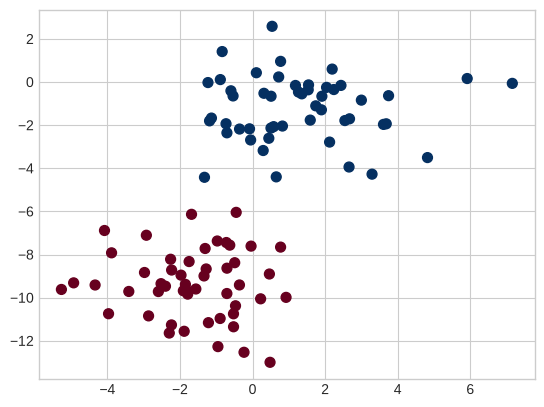

In [2]:
from sklearn.datasets import make_blobs
X, y = make_blobs(100, 2, centers=2, random_state=2, cluster_std=1.5)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='RdBu');

![Gaussian naive Bayes: the two blobs and the fitted Gaussian of each class](img/05.05-gaussian-NB.png)

*Static copy of the figure of {cite}`vanderplas2016python`; the cells above reproduce it.*

The ellipses here represent the Gaussian generative model for each label, with larger probability toward the center of the ellipses.
With this generative model in place for each class, we have a simple recipe to compute the likelihood $P({\rm features}~|~L_1)$ for any data point, and thus we can quickly compute the posterior ratio and determine which label is the most probable for a given point.

This procedure is implemented in Scikit-Learn's `sklearn.naive_bayes.GaussianNB` estimator:

In [3]:
from sklearn.naive_bayes import GaussianNB
model = GaussianNB()
model.fit(X, y);

Let's generate some new data and predict the label:

In [4]:
rng = np.random.RandomState(0)
Xnew = [-6, -14] + [14, 18] * rng.rand(2000, 2)
ynew = model.predict(Xnew)

Now we can plot this new data to see where the decision boundary falls:

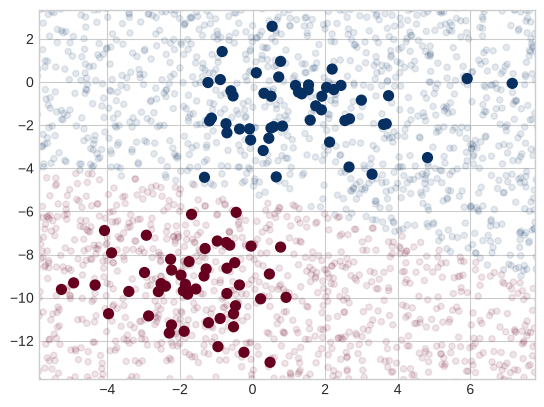

In [5]:
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='RdBu')
lim = plt.axis()
plt.scatter(Xnew[:, 0], Xnew[:, 1], c=ynew, s=20, cmap='RdBu', alpha=0.1)
plt.axis(lim);

We see a slightly curved boundary in the classifications: in general, the boundary produced by a Gaussian naive Bayes model is quadratic.

A nice aspect of this formalism is that it also gives a probabilistic classification, which we can read with the `predict_proba` method:

In [6]:
yprob = model.predict_proba(Xnew)
yprob[-8:].round(2)

array([[0.89, 0.11],
       [1.  , 0.  ],
       [1.  , 0.  ],
       [1.  , 0.  ],
       [1.  , 0.  ],
       [1.  , 0.  ],
       [0.  , 1.  ],
       [0.15, 0.85]])

The columns give the posterior probabilities of the first and second labels, respectively.
If you are looking for estimates of uncertainty in your classification, Bayesian approaches like this can be a good place to start.

Of course, the final classification will only be as good as the model assumptions that lead to it, which is why Gaussian naive Bayes often does not produce very good results.
Still, in many cases—especially as the number of features becomes large—this assumption is not detrimental enough to prevent Gaussian naive Bayes from being a reliable method.

## Multinomial Naive Bayes

The Gaussian assumption is not the only simple one. **Multinomial naive Bayes** takes each
feature to be generated from a multinomial distribution, which describes the probability of
observing counts across a number of categories. It is therefore the right choice when the
features are counts or count rates — most often word counts in a document.

The recipe is unchanged: replace the best-fit Gaussian by the best-fit multinomial and plug the
likelihoods into the same decision rule.


### Example: Classifying Text

One place where multinomial naive Bayes is used is text classification, where the features are word counts or frequencies inside the documents. Here we use the sparse word count features of the 20 Newsgroups corpus, available through Scikit-Learn.

The first call downloads the corpus (about 20 MB) and caches it under `~/scikit_learn_data`, so the cells below need a network connection only once:

In [7]:
from sklearn.datasets import fetch_20newsgroups

data = fetch_20newsgroups()
data.target_names

['alt.atheism',
 'comp.graphics',
 'comp.os.ms-windows.misc',
 'comp.sys.ibm.pc.hardware',
 'comp.sys.mac.hardware',
 'comp.windows.x',
 'misc.forsale',
 'rec.autos',
 'rec.motorcycles',
 'rec.sport.baseball',
 'rec.sport.hockey',
 'sci.crypt',
 'sci.electronics',
 'sci.med',
 'sci.space',
 'soc.religion.christian',
 'talk.politics.guns',
 'talk.politics.mideast',
 'talk.politics.misc',
 'talk.religion.misc']

For simplicity here, we will select just a few of these categories and download the training and testing sets:

In [8]:
categories = ['talk.religion.misc', 'soc.religion.christian',
              'sci.space', 'comp.graphics']
train = fetch_20newsgroups(subset='train', categories=categories)
test = fetch_20newsgroups(subset='test', categories=categories)

Here is a representative entry from the data:

In [9]:
print(train.data[5][48:])

Subject: Federal Hearing
Originator: dmcgee@uluhe
Organization: School of Ocean and Earth Science and Technology
Distribution: usa
Lines: 10


Fact or rumor....?  Madalyn Murray O'Hare an atheist who eliminated the
use of the bible reading and prayer in public schools 15 years ago is now
going to appear before the FCC with a petition to stop the reading of the
Gospel on the airways of America.  And she is also campaigning to remove
Christmas programs, songs, etc from the public schools.  If it is true
then mail to Federal Communications Commission 1919 H Street Washington DC
20054 expressing your opposition to her request.  Reference Petition number

2493.



In order to use this data for machine learning, we need to be able to convert the content of each string into a vector of numbers.
For this we will use the TF-IDF vectorizer, and create a pipeline that attaches it to a multinomial naive Bayes classifier:

In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import make_pipeline

model = make_pipeline(TfidfVectorizer(), MultinomialNB())

With this pipeline, we can apply the model to the training data and predict labels for the test data:

In [11]:
model.fit(train.data, train.target)
labels = model.predict(test.data)

Now that we have predicted the labels for the test data, we can evaluate the estimator. For example, the confusion matrix between the true and the predicted labels:

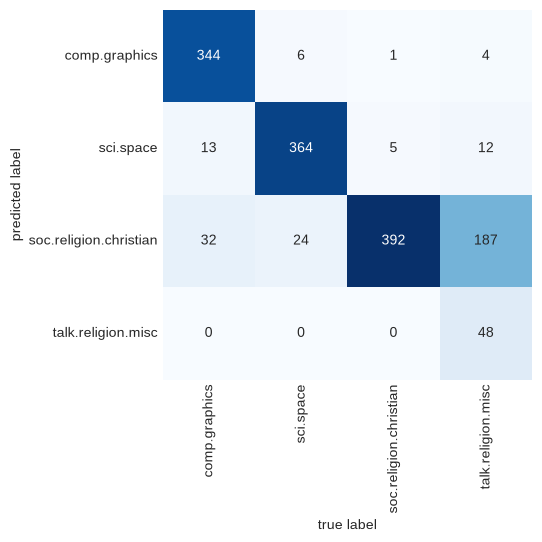

In [12]:
from sklearn.metrics import confusion_matrix
mat = confusion_matrix(test.target, labels)
sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False,
            xticklabels=train.target_names, yticklabels=train.target_names,
            cmap='Blues')
plt.xlabel('true label')
plt.ylabel('predicted label');

Evidently, even this very simple classifier can successfully separate space discussions from computer discussions, but it gets confused between discussions about religion and discussions about Christianity.
This is perhaps to be expected!

The cool thing here is that we now have the tools to determine the category for *any* string, using the `predict` method of this pipeline.
Here's a utility function that will return the prediction for a single string:

In [13]:
def predict_category(s, train=train, model=model):
    pred = model.predict([s])
    return train.target_names[pred[0]]

Let's try it out:

In [14]:
predict_category('sending a payload to the ISS')

'sci.space'

In [15]:
predict_category('discussing the existence of God')

'soc.religion.christian'

In [16]:
predict_category('determining the screen resolution')

'comp.graphics'

Remember that this is nothing more sophisticated than a simple probability model for the (weighted) frequency of each word in the string; nevertheless, the result is striking.
Even a very naive algorithm, when used carefully and trained on a large set of high-dimensional data, can be surprisingly effective.

## Naive Bayes versus k-NN, and When to Use It

k-NN and naive Bayes are both classifiers, but they build "similarity" differently. k-NN
models *nearness* — Euclidean or cosine distance — and keeps the training data around; naive
Bayes models *probability* — a generative distribution per class — and keeps only its
parameters.

Because its assumptions are so strong, naive Bayes will rarely beat a more flexible model on
the same data. What it offers instead:

*  training and prediction are a single pass over counts or means;
*  the output is a probability, not only a label;
*  the parameters are readable: they say which feature favoured which class;
*  there is essentially nothing to tune.

That makes it a good first baseline, as noted in {cite}`ESLII_print12`. If it does well you
have a very fast and very interpretable classifier; if it does not, you have a reference point
for how much a more complex model actually buys. It tends to do particularly well

*  when the independence assumption more or less holds (rare);
*  for well-separated classes, where model complexity matters little;
*  in very high dimension, where flexible models need far more data than are available.

The last two points are related: in high dimension two points are rarely close, so clusters are
further apart, and a simple model can separate them.


## Summary

Naive Bayes classifies by the posterior,
$P(\omega_j \mid \mathbf{x}) \propto P(\omega_j)\,p(\mathbf{x} \mid \omega_j)$, and the naive
assumption factorises the likelihood over the features. Everything else is a choice of the
one-dimensional model:

*  discrete features: count the values, with Laplace smoothing;
*  continuous features: a Gaussian per feature per class (Gaussian NB);
*  word counts: a multinomial per class (multinomial NB), usually on TF-IDF features.

Two warnings. The independence assumption makes the estimated likelihood of the evidence too
small, so the *probabilities* are usually over-confident; the ranking of the classes is much
better than the numbers attached to it. And a single unseen feature value zeroes a class unless
it is smoothed.
